# 03 · Post-training pitch-rate scaling
Nominal pitch rate $\dot\beta = \kappa_t\,\Delta\beta / T_{s,\mathrm{test}}$ with $\Delta\beta = 0.010^\circ$ and $T_{s,\mathrm{test}} = 0.025$ s (0.4 °/s for $\kappa_t = 1$).

* Fixed-rate sweeps in the 10 m/s transition profile and in the turbulent scenarios (data of Fig. 5).
* **Adaptive rule (two levels):** 0.8 °/s when $|P - P_{\mathrm{rated}}| > 0.1$ MW, otherwise 0.3 °/s; activity of each level.
* Table 5 (`tab:best`): adaptive rule in the full-load and turbulent scenarios.
* Diagnostic test at 10 m/s (0.004 °/s with a −1° pitch offset below rated), quoted only in the discussion.

Analysis window: 200–5200 s.

In [2]:
import numpy as np
import pandas as pd
from utils import load_fast_file, window, compare_to_rosco, CHANNELS, P_RATED, FIG_DIR

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)

ADAPTIVE = "0.8/0.3 °/s (adaptive)"
THRESHOLD = 100.0  # kW, power deviation that triggers the fast rate

# scenario -> ROSCO file, fixed-rate DDQN files {rate [°/s]: file}, adaptive-rule file
SWEEPS = {
    "10 m/s sawtooth": {
        "rosco": "val_saw10_rosco.out",
        "fixed": {0.004: "val_saw10_ddqn_0.004dps.out", 0.04: "val_saw10_ddqn_0.04dps.out",
                  0.3: "val_saw10_ddqn_0.3dps.out", 0.4: "val_saw10_ddqn_0.4dps.out",
                  0.6: "val_saw10_ddqn_0.6dps.out"},
        "adaptive": None,  # not applied: no power/load trade-off in the transition profile
    },
    "15 m/s sawtooth": {
        "rosco": "val_saw15_rosco.out",
        "fixed": {},
        "adaptive": "val_saw15_ddqn_0.8-0.3dps.out",
    },
    "11 m/s TI=10%": {
        "rosco": "val_11ti10_rosco.out",
        "fixed": {0.3: "val_11ti10_ddqn_0.3dps.out", 0.4: "val_11ti10_ddqn_0.4dps.out",
                  0.6: "val_11ti10_ddqn_0.6dps.out", 0.8: "val_11ti10_ddqn_0.8dps.out"},
        "adaptive": "val_11ti10_ddqn_0.8-0.3dps.out",
    },
    "15 m/s TI=10%": {
        "rosco": "val_15ti10_rosco.out",
        "fixed": {0.4: "val_15ti10_ddqn_0.4dps.out", 0.8: "val_15ti10_ddqn_0.8dps.out"},
        "adaptive": "val_15ti10_ddqn_0.8-0.3dps.out",
    },
}

# Diagnostic test (discussion only): 0.004 °/s with a -1° pitch offset for v < v_rated
DIAGNOSTIC = "val_saw10_ddqn_0.004dps_off-1-below.out"

In [3]:
# Run all comparisons once
tables, adaptive_runs = {}, {}
for scenario, cfg in SWEEPS.items():
    rosco = load_fast_file(cfg["rosco"])[0]
    cases = {f"{rate} °/s": load_fast_file(f)[0] for rate, f in cfg["fixed"].items()}
    if cfg["adaptive"]:
        adaptive_runs[scenario] = load_fast_file(cfg["adaptive"])[0]
        cases[ADAPTIVE] = adaptive_runs[scenario]
    tables[scenario] = compare_to_rosco(rosco, cases)

## 10 m/s sawtooth (transition): fixed rates

In [4]:
tables["10 m/s sawtooth"]

,ROSCO,0.004 °/s,0.04 °/s,0.3 °/s,0.4 °/s,0.6 °/s
GenPwr mean,3229.896,3371.980,3370.216,3371.753,3372.573,3374.485
GenPwr scaled STD,0.367,0.126,0.137,0.218,0.247,0.301
TwrBsMyt mean,51507.237,55603.937,55489.167,55229.902,55208.576,55371.198
TwrBsMyt scaled STD,0.269,0.304,0.357,0.745,0.890,1.169
RootMyb1 mean,7492.026,8020.954,8005.425,7975.308,7974.292,7997.771
RootMyb1 scaled STD,0.230,0.250,0.286,0.572,0.683,0.897
Last time step [s],5500.000,5250.025,5250.025,5250.000,5250.000,5250.025


## 10 m/s sawtooth: operating point and phase of the pitch response
The wind oscillates between 9.5 and 10.5 m/s with a 20 s period. Two effects are separated here:

* **Operating point** (mean values): mean pitch, generator torque, mean power and mean TB moment.
* **Phase of the pitch response** (variability): phase-averaged signals over the 20 s wind cycle show whether
  the pitch moves in phase with the wind (as ROSCO does, damping the thrust variation) or out of phase
  (lowering the pitch while the wind rises, which amplifies the thrust and TB oscillation).


In [5]:
PERIOD = 20.0   # s, period of the sawtooth wind
BIN = 1.0       # s, width of the phase bins

saw10 = SWEEPS["10 m/s sawtooth"]
cycle_runs = {"ROSCO": window(load_fast_file(saw10["rosco"])[0])}
for rate, f in saw10["fixed"].items():
    cycle_runs[f"{rate} °/s"] = window(load_fast_file(f)[0])
cycle_runs["0.004 °/s + offset"] = window(load_fast_file(DIAGNOSTIC)[0])

# Operating point (means) and variability (standard deviations) in physical units
dt = cycle_runs["ROSCO"]["Time"].diff().median()
op = {}
for label, d in cycle_runs.items():
    op[label] = {
        "Pitch mean [deg]": d["BldPitch1"].mean(),
        "Pitch STD [deg]": d["BldPitch1"].std(),
        "Pitch travel [deg/h]": np.abs(np.diff(d["BldPitch1"])).sum() / (len(d) * dt / 3600),
        "GenTq mean [kN·m]": d["GenTq"].mean(),
        "GenTq STD [kN·m]": d["GenTq"].std(),
        "RotSpeed max [rpm]": d["RotSpeed"].max(),
        "Power mean [kW]": d["GenPwr"].mean(),
        "Power max [kW]": d["GenPwr"].max(),
        "TB mean [MN·m]": d["TwrBsMyt"].mean() / 1e3,
        "TB STD [MN·m]": d["TwrBsMyt"].std() / 1e3,
    }
pd.DataFrame(op).round(3)


,ROSCO,0.004 °/s,0.04 °/s,0.3 °/s,0.4 °/s,0.6 °/s,0.004 °/s + offset
Pitch mean [deg],4.211,3.334,3.354,3.399,3.395,3.325,3.293
Pitch STD [deg],0.574,0.034,0.115,0.866,1.154,1.732,0.477
Pitch travel [deg/h],592.446,15.524,156.105,1181.608,1578.837,2372.997,2475.784
GenTq mean [kN·m],27.848,29.080,29.080,29.080,29.080,29.080,29.080
GenTq STD [kN·m],1.536,0.000,0.000,0.000,0.000,0.000,0.000
RotSpeed max [rpm],11.920,12.160,12.050,12.290,12.380,12.550,12.060
Power mean [kW],3229.896,3371.980,3370.216,3371.753,3372.573,3374.485,3370.118
Power max [kW],3453.000,3522.000,3490.000,3561.000,3586.000,3635.000,3493.000
TB mean [MN·m],51.507,55.604,55.489,55.230,55.209,55.371,55.791
TB STD [MN·m],3.300,3.735,4.386,9.139,10.926,14.344,3.002


In [6]:
def phase_average(d, channels, period=PERIOD, width=BIN):
    """Mean of each channel in bins of `width` seconds within the wind cycle."""
    phase = ((d["Time"] - d["Time"].iloc[0]) % period)
    bins = (phase // width) * width
    return d.groupby(bins)[channels].mean()

CYCLE_CHANNELS = ["Wind1VelX", "BldPitch1", "RotSpeed", "GenPwr", "TwrBsMyt"]
CYCLE_CASES = ["ROSCO", "0.004 °/s", "0.004 °/s + offset", "0.4 °/s"]

cycles = {}
for label in CYCLE_CASES:
    c = phase_average(cycle_runs[label], CYCLE_CHANNELS)
    c["TwrBsMyt"] = c["TwrBsMyt"] / 1e3   # MN·m
    cycles[label] = c
    print(f"== {label}")
    display(c.round(2).T)


== ROSCO


Time,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0,14.0,15.0,16.0,17.0,18.0,19.0
Wind1VelX,9.51,9.56,9.66,9.78,9.92,10.07,10.22,10.34,10.44,10.49,10.49,10.44,10.34,10.22,10.08,9.93,9.78,9.66,9.56,9.51
BldPitch1,3.81,3.73,3.65,3.59,3.54,3.50,3.51,3.88,4.27,4.59,4.83,5.02,5.11,5.09,4.97,4.75,4.46,4.11,3.94,3.88
RotSpeed,11.34,11.32,11.34,11.39,11.47,11.57,11.68,11.78,11.84,11.88,11.91,11.91,11.89,11.85,11.78,11.71,11.62,11.54,11.45,11.38
GenPwr,2991.52,2897.20,2851.57,2855.23,2908.24,3014.61,3156.38,3335.62,3430.83,3442.68,3449.82,3451.01,3444.41,3431.62,3413.10,3390.83,3366.70,3341.81,3293.63,3131.11
TwrBsMyt,48.71,49.62,50.48,52.59,54.04,56.17,57.97,57.86,54.88,54.40,52.65,50.89,49.82,48.39,48.15,47.90,48.35,49.16,49.75,48.36


== 0.004 °/s


Time,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0,14.0,15.0,16.0,17.0,18.0,19.0
Wind1VelX,9.51,9.56,9.66,9.78,9.92,10.07,10.22,10.34,10.44,10.49,10.49,10.44,10.34,10.22,10.08,9.93,9.78,9.66,9.56,9.51
BldPitch1,3.35,3.35,3.34,3.34,3.34,3.33,3.33,3.32,3.32,3.32,3.32,3.32,3.32,3.33,3.33,3.34,3.34,3.34,3.35,3.35
RotSpeed,11.58,11.47,11.38,11.31,11.27,11.27,11.31,11.37,11.47,11.58,11.70,11.81,11.91,11.98,12.01,12.01,11.97,11.90,11.81,11.70
GenPwr,3355.57,3323.55,3296.37,3276.56,3265.83,3265.21,3274.84,3294.05,3321.31,3354.09,3389.03,3422.11,3449.65,3469.09,3478.83,3478.21,3467.52,3447.83,3420.87,3389.05
TwrBsMyt,50.42,50.47,50.99,51.89,53.11,54.51,56.05,57.57,59.00,60.15,60.84,60.88,60.42,59.50,58.18,56.66,55.00,53.42,52.03,50.97


== 0.004 °/s + offset


Time,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0,14.0,15.0,16.0,17.0,18.0,19.0
Wind1VelX,9.51,9.56,9.66,9.78,9.92,10.07,10.22,10.34,10.44,10.49,10.49,10.44,10.34,10.22,10.08,9.93,9.78,9.66,9.56,9.51
BldPitch1,2.67,2.67,2.67,2.95,3.66,3.66,3.65,3.65,3.64,3.64,3.64,3.64,3.65,3.65,3.65,3.66,3.10,2.67,2.67,2.67
RotSpeed,11.63,11.57,11.51,11.47,11.43,11.38,11.37,11.41,11.47,11.56,11.65,11.74,11.82,11.86,11.88,11.86,11.82,11.79,11.76,11.71
GenPwr,3369.50,3350.43,3332.87,3322.78,3310.38,3297.40,3294.70,3305.01,3322.22,3347.40,3374.84,3400.96,3422.85,3436.41,3441.64,3436.59,3423.46,3415.47,3406.55,3390.92
TwrBsMyt,56.57,52.81,56.83,55.27,50.47,51.41,55.74,53.74,58.25,57.30,58.64,59.01,57.45,57.69,55.39,54.44,53.37,61.13,55.67,54.64


== 0.4 °/s


Time,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0,14.0,15.0,16.0,17.0,18.0,19.0
Wind1VelX,9.51,9.56,9.66,9.78,9.92,10.07,10.22,10.34,10.44,10.49,10.49,10.44,10.34,10.22,10.08,9.93,9.78,9.66,9.56,9.51
BldPitch1,4.92,4.52,4.12,3.72,3.32,2.92,2.52,2.12,1.72,1.51,1.87,2.27,2.67,3.07,3.47,3.87,4.27,4.67,5.07,5.28
RotSpeed,11.35,11.16,11.02,10.95,10.93,10.98,11.08,11.24,11.45,11.69,11.93,12.13,12.28,12.36,12.37,12.31,12.20,12.03,11.82,11.58
GenPwr,3286.60,3231.48,3193.19,3170.91,3166.57,3179.76,3209.77,3255.91,3315.25,3385.36,3456.24,3515.13,3556.35,3579.42,3582.68,3567.03,3534.15,3485.76,3424.97,3354.93
TwrBsMyt,39.79,43.99,45.36,49.95,52.54,56.40,60.48,63.90,68.54,72.01,71.58,68.28,66.63,61.75,58.01,53.36,48.60,44.74,40.51,37.73


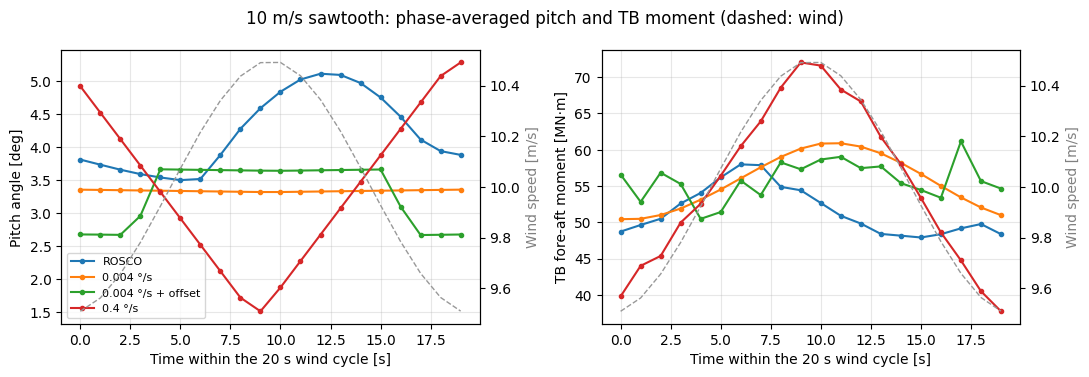

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
wind = cycles["ROSCO"]["Wind1VelX"]
for label, c in cycles.items():
    axes[0].plot(c.index, c["BldPitch1"], marker="o", ms=3, label=label)
    axes[1].plot(c.index, c["TwrBsMyt"], marker="o", ms=3, label=label)
axes[0].set_ylabel("Pitch angle [deg]")
axes[1].set_ylabel("TB fore-aft moment [MN·m]")
for ax in axes:
    ax.set_xlabel("Time within the 20 s wind cycle [s]")
    ax.grid(alpha=0.3)
    twin = ax.twinx()
    twin.plot(wind.index, wind, color="0.6", ls="--", lw=1)
    twin.set_ylabel("Wind speed [m/s]", color="0.5")
axes[0].legend(fontsize=8, loc="lower left")
fig.suptitle("10 m/s sawtooth: phase-averaged pitch and TB moment (dashed: wind)")
fig.tight_layout()
plt.show()


## 15 m/s sawtooth (full load): adaptive rule

In [8]:
tables["15 m/s sawtooth"]

,ROSCO,0.8/0.3 °/s (adaptive)
GenPwr mean,3369.731,3375.923
GenPwr scaled STD,0.344,0.122
TwrBsMyt mean,29408.855,29548.784
TwrBsMyt scaled STD,0.288,0.249
RootMyb1 mean,3980.567,4000.835
RootMyb1 scaled STD,0.238,0.230
Last time step [s],5500.000,5250.025


## 11 m/s TI = 10 % (design scenario of the adaptive rule)

In [9]:
tables["11 m/s TI=10%"]

,ROSCO,0.3 °/s,0.4 °/s,0.6 °/s,0.8 °/s,0.8/0.3 °/s (adaptive)
GenPwr mean,3347.209,3371.332,3370.575,3370.164,3369.611,3369.145
GenPwr scaled STD,0.105,0.120,0.084,0.068,0.069,0.063
TwrBsMyt mean,45099.925,45805.174,45808.552,45772.238,45743.865,45770.090
TwrBsMyt scaled STD,0.122,0.185,0.184,0.205,0.232,0.179
RootMyb1 mean,6384.686,6480.521,6479.518,6474.730,6472.677,6473.298
RootMyb1 scaled STD,0.130,0.164,0.162,0.171,0.184,0.160
Last time step [s],5500.000,5250.000,5250.000,5250.000,5250.025,5250.000


## 15 m/s TI = 10 %

In [10]:
tables["15 m/s TI=10%"]

,ROSCO,0.4 °/s,0.8 °/s,0.8/0.3 °/s (adaptive)
GenPwr mean,3370.621,3378.631,3375.661,3373.565
GenPwr scaled STD,0.137,0.077,0.055,0.056
TwrBsMyt mean,30183.345,30316.449,30310.146,30266.286
TwrBsMyt scaled STD,0.119,0.143,0.189,0.134
RootMyb1 mean,3888.210,3911.416,3912.167,3903.842
RootMyb1 scaled STD,0.148,0.156,0.166,0.152
Last time step [s],5500.000,5250.000,5250.000,5250.025


## Activity of the adaptive rule
Fraction of time at the fast rate (|P − P_rated| > 0.1 MW) and duration of the fast-rate episodes.

In [11]:
rows = []
for scenario, df in adaptive_runs.items():
    d = window(df)
    fast = (np.abs(P_RATED - d["GenPwr"]) > THRESHOLD).to_numpy().astype(int)
    edges = np.diff(np.r_[0, fast, 0])
    durations = (np.flatnonzero(edges == -1) - np.flatnonzero(edges == 1)) * d["Time"].diff().median()
    rows.append({"Scenario": scenario,
                 "Time at 0.8 °/s [%]": 100 * fast.mean(),
                 "Fast episodes": len(durations),
                 "Median episode [s]": np.median(durations) if len(durations) else np.nan,
                 "90th pct episode [s]": np.percentile(durations, 90) if len(durations) else np.nan})
pd.DataFrame(rows).set_index("Scenario").round(2)

,Time at 0.8 °/s [%],Fast episodes,Median episode [s],90th pct episode [s]
Scenario,,,,
15 m/s sawtooth,0.07,2,1.8,2.00
11 m/s TI=10%,11.80,198,2.9,5.09
15 m/s TI=10%,7.05,202,1.4,3.69


## Table 5: adaptive rule

In [12]:
rows = {}
for scenario, cfg in SWEEPS.items():
    if not cfg["adaptive"]:
        continue
    t = tables[scenario]
    col = {}
    for ch in CHANNELS:
        col[f"{ch} mean DDQN"] = t.loc[f"{ch} mean", ADAPTIVE]
        col[f"{ch} mean ROSCO"] = t.loc[f"{ch} mean", "ROSCO"]
        col[f"{ch} scaled STD DDQN"] = t.loc[f"{ch} scaled STD", ADAPTIVE]
        col[f"{ch} scaled STD ROSCO"] = t.loc[f"{ch} scaled STD", "ROSCO"]
    rows[scenario] = col
table5 = pd.DataFrame(rows)
table5

,15 m/s sawtooth,11 m/s TI=10%,15 m/s TI=10%
GenPwr mean DDQN,3375.923,3369.145,3373.565
GenPwr mean ROSCO,3369.731,3347.209,3370.621
GenPwr scaled STD DDQN,0.122,0.063,0.056
GenPwr scaled STD ROSCO,0.344,0.105,0.137
TwrBsMyt mean DDQN,29548.784,45770.090,30266.286
TwrBsMyt mean ROSCO,29408.855,45099.925,30183.345
TwrBsMyt scaled STD DDQN,0.249,0.179,0.134
TwrBsMyt scaled STD ROSCO,0.288,0.122,0.119
RootMyb1 mean DDQN,4000.835,6473.298,3903.842
RootMyb1 mean ROSCO,3980.567,6384.686,3888.210


## Data for Fig. 5
* Panel A, 10 m/s sawtooth: fixed rates 0.004, 0.04, 0.4 and 0.6 °/s.
* Panel B, 11 m/s TI = 10 %: fixed rates 0.3–0.8 °/s and the two-level adaptive rule.

Saved to `Figures/fig5_data.csv` and read by `05_paper_figures.ipynb`.

In [13]:
# panel -> scenario, {series: {x: column in tables[scenario]}}
FIG5 = {
    "A": ("10 m/s sawtooth", {
        "fixed": {0.004: "0.004 °/s", 0.04: "0.04 °/s", 0.4: "0.4 °/s", 0.6: "0.6 °/s"},
    }),
    "B": ("11 m/s TI=10%", {
        "fixed": {0.3: "0.3 °/s", 0.4: "0.4 °/s", 0.6: "0.6 °/s", 0.8: "0.8 °/s"},
        "adaptive": {0: ADAPTIVE},
    }),
}

records = []
for panel, (scenario, series) in FIG5.items():
    t = tables[scenario]
    for ch in CHANNELS:
        for kind, columns in {**series, "rosco": {0: "ROSCO"}}.items():
            for x, col in columns.items():
                records.append({"panel": panel, "scenario": scenario, "series": kind, "x": x,
                                "channel": ch, "scaled_std": t.loc[f"{ch} scaled STD", col]})
fig5 = pd.DataFrame(records)
FIG_DIR.mkdir(exist_ok=True)
fig5.to_csv(FIG_DIR / "fig5_data.csv", index=False)
fig5.round(3)

,panel,scenario,series,x,channel,scaled_std
0,A,10 m/s sawtooth,fixed,0.004,GenPwr,0.126
1,A,10 m/s sawtooth,fixed,0.040,GenPwr,0.137
2,A,10 m/s sawtooth,fixed,0.400,GenPwr,0.247
3,A,10 m/s sawtooth,fixed,0.600,GenPwr,0.301
4,A,10 m/s sawtooth,rosco,0.000,GenPwr,0.367
5,A,10 m/s sawtooth,fixed,0.004,TwrBsMyt,0.304
6,A,10 m/s sawtooth,fixed,0.040,TwrBsMyt,0.357
7,A,10 m/s sawtooth,fixed,0.400,TwrBsMyt,0.890
8,A,10 m/s sawtooth,fixed,0.600,TwrBsMyt,1.169
9,A,10 m/s sawtooth,rosco,0.000,TwrBsMyt,0.269
